# Оценка робастности систем лучевой диагностики к состязательным атакам Карлини-Вагнера ($C\&W\text{ }L_2$) на рентгенограммах органов грудной клетки

В системах компьютерного анализа медицинских изображений (CAD/CDSS) критическое значение имеет устойчивость глубоких сверточных сетей к высокочастотным аддитивным возмущениям. Настоящее исследование посвящено моделированию направленных состязательных искажений в задачах цифровой рентгенографии органов грудной клетки (CXR) и разработке эшелонированной защиты.

**Метрики и цели исследования:**
1. Построение робастного вероятностного классификатора патологий (бинарная классификация: `NORMAL` vs `PNEUMONIA`) на основе глубокой архитектуры ResNet-18 с тонкой настройкой (Fine-tuning) высокоуровневых слоев.
2. Имплементация ресурсоемкой квази-ньютоновской атаки второго порядка Карлини-Вагнера в $L_2$-метрике с 6-ступенчатым бинарным поиском множителя Лагранжа.
3. Оценка диагностической уязвимости: вычисление индекса структурного сходства ($\text{SSIM}$) и норм искажения ($L_2$, $L_\infty$).
4. Развертывание мультимодальной системы защиты: пространственно-битового сжатия (Feature Squeezing) и тяжелого состязательного обучения (Adversarial Training $\text{PGD}_{10}$).

In [1]:
import os
import math
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
import kagglehub
from PIL import Image

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Загрузка биомедицинского датасета рентгенограмм и балансировка выборки

Используется репрезентативная выборка рентгенограмм грудной клетки в передне-задней проекции (CXR). Выделяются два клинических класса:
1. $\mathcal{C}_0$ (`NORMAL`): контрольная группа без инфильтративных изменений.
2. $\mathcal{C}_1$ (`PNEUMONIA`): подтвержденный диагноз бактериальной или вирусной пневмонии.

Для обеспечения статистической значимости и устранения смещения распределения (Class Imbalance) формируется сбалансированная выборка из $3000$ изображений. Инвариантность классификатора к позиционированию пациента достигается геометрической аугментацией $\mathcal{T}_{aug}$:
$$\mathcal{T}_{aug} = \mathcal{R}_{affine}(\theta \sim \mathcal{U}(-10^\circ, 10^\circ)) \circ \mathcal{S}_{resize}$$

In [2]:
try:
    download_dir = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
except:
    download_dir = "/kaggle/input"

normal_files = []
pneumonia_files = []

for base_path in [download_dir, "/kaggle/input"]:
    if not os.path.exists(base_path):
        continue
    for root, dirs, files in os.walk(base_path):
        if "__MACOSX" in root:
            continue
        for f in files:
            if f.startswith("."):
                continue
            if not f.lower().endswith((".jpeg", ".jpg", ".png")):
                continue
            full_path = os.path.join(root, f)
            if "NORMAL" in root:
                normal_files.append(full_path)
            elif "PNEUMONIA" in root:
                pneumonia_files.append(full_path)
    if len(normal_files) >= 1500 and len(pneumonia_files) >= 1500:
        break

normal_files = sorted(list(set(normal_files)))[:1500]
pneumonia_files = sorted(list(set(pneumonia_files)))[:1500]

all_files = normal_files + pneumonia_files
all_labels = [0] * len(normal_files) + [1] * len(pneumonia_files)

indices = np.arange(len(all_files))
np.random.seed(42)
np.random.shuffle(indices)

total_len = len(indices)
train_len = int(0.8 * total_len)

train_indices = indices[:train_len]
val_indices = indices[train_len:]

train_files = [all_files[i] for i in train_indices]
train_labels = [all_labels[i] for i in train_indices]
val_files = [all_files[i] for i in val_indices]
val_labels = [all_labels[i] for i in val_indices]

class MedicalXRayDataset(Dataset):
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        path = self.file_paths[idx]
        with Image.open(path) as img:
            img = img.convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor()
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_data = MedicalXRayDataset(train_files, train_labels, train_transform)
val_data = MedicalXRayDataset(val_files, val_labels, eval_transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False, num_workers=2)
attack_loader = DataLoader(val_data, batch_size=1, shuffle=False)

## Дифференцируемая модель лучевой диагностики

В качестве основы компьютерного зрения развертывается глубокая сверточная сеть ResNet-18 со встроенным дифференцируемым слоем нормализации, обеспечивающим корректный расчет градиентов без выхода за пределы интенсивности рентгеновской трубки:
$$\mathcal{M}_{CXR}(x) = f_{backbone}\left( \frac{x - \mu}{\sigma} \right)$$
где $\mu = [0.485, 0.456, 0.406]^T$, $\sigma = [0.229, 0.224, 0.225]^T$. Обучению (Fine-Tuning) подлежат блоки извлечения патологических паттернов `layer3`, `layer4` и классификатор `fc`:
$$\min_{\theta} \left\{ \frac{1}{B} \sum_{i=1}^B \mathcal{L}_{CE}(\mathcal{M}_{CXR}(x_i), y_i) + \lambda \|\theta\|_2^2 \right\}$$

In [3]:
class NormalizedMedicalResNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        for param in backbone.parameters():
            param.requires_grad = False
            
        for param in backbone.layer3.parameters():
            param.requires_grad = True
        for param in backbone.layer4.parameters():
            param.requires_grad = True
            
        backbone.fc = nn.Linear(backbone.fc.in_features, num_classes)
        self.network = backbone

    def forward(self, x):
        x_norm = (x - self.mean) / self.std
        return self.network(x_norm)

model = NormalizedMedicalResNet(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW([
    {"params": model.network.layer3.parameters(), "lr": 5e-5},
    {"params": model.network.layer4.parameters(), "lr": 1e-4},
    {"params": model.network.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-4)

epochs = 10
train_losses = []
val_accuracies = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    total_train = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        total_train += inputs.size(0)
        
    epoch_loss = running_loss / total_train
    train_losses.append(epoch_loss)
    
    model.eval()
    correct = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            preds = model(inputs).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total_val += labels.size(0)
            
    val_acc = (correct / total_val) * 100.0
    val_accuracies.append(val_acc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


## Оптимизационная атака Карлини-Вагнера ($C\&W\text{ }L_2$) высокой вычислительной плотности

Атака моделирует внесение минимального аддитивного шума, приводящего к инверсии диагностического решения, при строгом соблюдении оптического диапазона пикселей $[0, 1]^D$:
$$x' = \frac{1}{2}(\tanh(w) + 1)$$
Оптимизируется взвешенная целевая функция:
$$\min_{w} \left\{ \left\| \frac{1}{2}(\tanh(w) + 1) - x \right\|_2^2 + c \cdot f(x') \right\}$$
где суррогат ошибки классификации выражается через разность логитов истинного диагноза $y$ и конкурирующего класса:
$$f(x') = \max\left(Z(x')_{y} - \max_{i \neq y} Z(x')_i, -\kappa\right)$$
Для достижения абсолютного минимума возмущения реализован 6-ступенчатый логарифмический бинарный поиск параметра $c$, требующий решения $100$ итераций оптимизации на каждый шаг.

In [4]:
def carlini_wagner_l2_heavy(model, x, y, search_steps=6, max_iter=100, lr=0.015, kappa=0.0, initial_c=1.0):
    x = x.to(device)
    y = y.to(device)
    batch_size = x.size(0)
    
    lower_bound = torch.zeros(batch_size, device=device)
    upper_bound = torch.full((batch_size,), 1e10, device=device)
    c_current = torch.full((batch_size,), initial_c, device=device)
    
    o_best_l2 = torch.full((batch_size,), float("inf"), device=device)
    o_best_adv = x.clone()
    
    w_init = torch.arctanh(torch.clamp((x * 2.0 - 1.0) * 0.999999, -1.0, 1.0))
    
    for step in range(search_steps):
        w = w_init.clone().detach().requires_grad_(True)
        opt = optim.Adam([w], lr=lr)
        
        current_best_l2 = torch.full((batch_size,), float("inf"), device=device)
        current_best_score = torch.full((batch_size,), -1, dtype=torch.long, device=device)
        
        for iteration in range(max_iter):
            x_adv = 0.5 * (torch.tanh(w) + 1.0)
            l2_dist = torch.sum((x_adv - x) ** 2, dim=[1, 2, 3])
            
            logits = model(x_adv)
            
            one_hot = torch.zeros_like(logits).scatter_(1, y.unsqueeze(1), 1.0)
            real_logit = torch.sum(one_hot * logits, dim=1)
            other_logit, _ = torch.max((1.0 - one_hot) * logits - one_hot * 1e4, dim=1)
            
            f_loss = torch.clamp(real_logit - other_logit + kappa, min=0.0)
            loss = torch.sum(l2_dist + c_current * f_loss)
            
            opt.zero_grad()
            loss.backward()
            opt.step()
            
            preds = logits.argmax(dim=1)
            for b in range(batch_size):
                if preds[b] != y[b] and l2_dist[b] < current_best_l2[b]:
                    current_best_l2[b] = l2_dist[b].item()
                    current_best_score[b] = preds[b]
                if preds[b] != y[b] and l2_dist[b] < o_best_l2[b]:
                    o_best_l2[b] = l2_dist[b].item()
                    o_best_adv[b] = x_adv[b].detach()
                    
        for b in range(batch_size):
            if current_best_score[b] != -1:
                upper_bound[b] = min(upper_bound[b], c_current[b])
                if upper_bound[b] < 1e9:
                    c_current[b] = (lower_bound[b] + upper_bound[b]) / 2.0
            else:
                lower_bound[b] = max(lower_bound[b], c_current[b])
                if upper_bound[b] < 1e9:
                    c_current[b] = (lower_bound[b] + upper_bound[b]) / 2.0
                else:
                    c_current[b] *= 10.0
                    
    return o_best_adv, o_best_l2

## Клинико-статистический бенчмарк состязательной уязвимости

Оценка проводится на массиве из $N = 200$ верифицированных рентгенограмм. В ходе генерации фиксируются метрики клинической незаметности вмешательства:
1. $L_2$-норма возмущения (евклидово расстояние в пространстве интенсивностей).
2. $L_\infty$-норма (максимальное локальное отклонение пикселя).
3. Индекс структурного сходства $\text{SSIM}$ (сохранение анатомической структуры легочных полей):
$$\text{SSIM}(x, x') = \frac{(2\mu_x\mu_{x'} + C_1)(2\sigma_{xx'} + C_2)}{(\mu_x^2 + \mu_{x'}^2 + C_1)(\sigma_x^2 + \sigma_{x'}^2 + C_2)}$$
4. Коэффициент успешности атаки (Attack Success Rate, ASR).

In [5]:
def compute_medical_ssim(img1, img2):
    C1 = (0.01) ** 2
    C2 = (0.03) ** 2
    mu1 = F.avg_pool2d(img1, kernel_size=11, stride=1, padding=5)
    mu2 = F.avg_pool2d(img2, kernel_size=11, stride=1, padding=5)
    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu1_mu2 = mu1 * mu2
    sigma1_sq = F.avg_pool2d(img1 * img1, kernel_size=11, stride=1, padding=5) - mu1_sq
    sigma2_sq = F.avg_pool2d(img2 * img2, kernel_size=11, stride=1, padding=5) - mu2_sq
    sigma12 = F.avg_pool2d(img1 * img2, kernel_size=11, stride=1, padding=5) - mu1_mu2
    ssim_map = ((2.0 * mu1_mu2 + C1) * (2.0 * sigma12 + C2)) / ((mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))
    return torch.mean(ssim_map, dim=[1, 2, 3])

benchmark_limit = 200
tested_samples = 0
successful_attacks = 0

l2_records = []
linf_records = []
ssim_records = []
adv_images_storage = []
clean_images_storage = []
targets_storage = []

for data, target in attack_loader:
    if tested_samples >= benchmark_limit:
        break
        
    data, target = data.to(device), target.to(device)
    with torch.no_grad():
        initial_pred = model(data).argmax(dim=1)
        
    if initial_pred != target:
        continue
        
    tested_samples += 1
    adv_x, l2_norm = carlini_wagner_l2_heavy(
        model, data, target, search_steps=6, max_iter=100, lr=0.015, kappa=0.0, initial_c=1.0
    )
    
    with torch.no_grad():
        adv_pred = model(adv_x).argmax(dim=1)
        
    if adv_pred != target:
        successful_attacks += 1
        diff = (adv_x - data).abs()
        l2_records.append(math.sqrt(l2_norm.item()))
        linf_records.append(diff.max().item())
        ssim_records.append(compute_medical_ssim(data, adv_x).item())
        
        adv_images_storage.append(adv_x.detach().cpu())
        clean_images_storage.append(data.detach().cpu())
        targets_storage.append(target.detach().cpu())

asr_metric = (successful_attacks / tested_samples) * 100.0 if tested_samples > 0 else 0.0

## Пассивная защита рентгенограмм: Медицинский Feature Squeezing

Для устранения состязательных возмущений применяется каскадный модуль фильтрации. Метод подавляет высокочастотный состязательный градиент за счет квантования градаций серого (Bit-Depth Squeezing, $b = 3$) и пространственной медианной фильтрации ($k = 3 \times 3$):
$$\mathcal{S}_{med}(x) = \text{MedianFilter}_{3\times3}\left( \frac{\lfloor (2^b - 1)x + 0.5 \rfloor}{2^b - 1} \right)$$
Данный метод легко интегрируется в пайплайн обработки PACS/DICOM систем без необходимости переобучения диагностической сети.

In [6]:
class MedicalFeatureSqueezer(nn.Module):
    def __init__(self, bit_depth=3, median_kernel=3, gaussian_sigma=1.0):
        super().__init__()
        self.bit_depth = bit_depth
        self.k = median_kernel
        self.pad = median_kernel // 2
        
        radius = 2
        kernel_size = 2 * radius + 1
        x = torch.arange(-radius, radius + 1, dtype=torch.float32)
        k1d = torch.exp(-0.5 * (x / gaussian_sigma) ** 2)
        k1d = k1d / k1d.sum()
        k2d = k1d.unsqueeze(1) * k1d.unsqueeze(0)
        self.register_buffer("gauss_kernel", k2d.view(1, 1, kernel_size, kernel_size).repeat(3, 1, 1, 1))

    def forward(self, x):
        bins = (2 ** self.bit_depth) - 1.0
        x_quant = torch.round(x * bins) / bins
        
        x_pad = F.pad(x_quant, (self.pad, self.pad, self.pad, self.pad), mode="reflect")
        patches = x_pad.unfold(2, self.k, 1).unfold(3, self.k, 1)
        patches = patches.contiguous().view(patches.size(0), patches.size(1), patches.size(2), patches.size(3), -1)
        x_med, _ = torch.median(patches, dim=-1)
        
        x_final = F.conv2d(x_med, self.gauss_kernel, padding=2, groups=3)
        return x_final

defense_transform = MedicalFeatureSqueezer(bit_depth=3, median_kernel=3, gaussian_sigma=1.0).to(device)

## Активная защита: Интенсивное состязательное дообучение (Adversarial Training $\text{PGD}_{10}$)

Фундаментальным рубежом защиты выступает перестройка гиперповерхности решений через минимаксную робастную оптимизацию по парадигме Мадри:
$$\min_{\theta} \mathbb{E}_{(x, y) \sim \mathcal{D}} \left[ \max_{\|\delta\|_\infty \le \epsilon} \mathcal{L}_{CE}(f_\theta(x + \delta), y) \right]$$
Генератор внутренних состязательных примеров применяет ресурсоемкий итеративный алгоритм PGD-10 (10 шагов спуска) с бюджетом возмущения $\epsilon = 0.08$.

In [7]:
def generate_heavy_pgd(model_instance, x_batch, y_batch, eps=0.08, alpha=0.015, steps=10):
    adv = x_batch.clone().detach() + torch.FloatTensor(*x_batch.shape).uniform_(-eps, eps).to(device)
    adv = torch.clamp(adv, 0.0, 1.0)
    
    for _ in range(steps):
        adv.requires_grad = True
        out = model_instance(adv)
        loss_val = criterion(out, y_batch)
        model_instance.zero_grad()
        loss_val.backward()
        
        with torch.no_grad():
            grad_sign = adv.grad.sign()
            adv = adv + alpha * grad_sign
            eta = torch.clamp(adv - x_batch, -eps, eps)
            adv = torch.clamp(x_batch + eta, 0.0, 1.0)
            
    return adv.detach()

robust_medical_model = NormalizedMedicalResNet(num_classes=2).to(device)
robust_medical_model.load_state_dict(model.state_dict())

robust_optimizer = optim.AdamW([
    {"params": robust_medical_model.network.layer3.parameters(), "lr": 5e-5},
    {"params": robust_medical_model.network.layer4.parameters(), "lr": 1e-4},
    {"params": robust_medical_model.network.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-4)

retrain_epochs = 5
for r_epoch in range(retrain_epochs):
    robust_medical_model.train()
    for inps, lbls in train_loader:
        inps, lbls = inps.to(device), lbls.to(device)
        inps_adv = generate_heavy_pgd(robust_medical_model, inps, lbls, eps=0.08, alpha=0.015, steps=10)
        
        robust_optimizer.zero_grad()
        outputs = robust_medical_model(inps_adv)
        loss_robust = criterion(outputs, lbls)
        loss_robust.backward()
        robust_optimizer.step()

robust_medical_model.eval()

NormalizedMedicalResNet(
  (network): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine

## Статистическая оценка эффективности восстановления диагноза

Эффективность защитных контуров оценивается через показатель восстановления диагноза (Diagnostic Recovery Rate, DRR):
$$\text{DRR} = \frac{1}{|\mathcal{A}|} \sum_{x' \in \mathcal{A}} \mathbb{I}\left( \mathcal{M}_{def}(x') = y_{true} \right) \times 100\%$$
где $\mathcal{A}$ — совокупность рентгенограмм с успешно реализованной инверсией диагноза.

In [8]:
clean_correct_cnt = 0
attack_recovered_fs = 0
attack_recovered_rob = 0
total_adv_samples = len(adv_images_storage)

all_clean_preds = []
all_adv_preds = []
all_def_fs_preds = []
all_def_rob_preds = []
ground_truths = []

model.eval()
with torch.no_grad():
    for i in range(total_adv_samples):
        x_clean = clean_images_storage[i].to(device)
        x_adv = adv_images_storage[i].to(device)
        label = targets_storage[i].to(device)
        
        p_clean = model(x_clean).argmax(dim=1)
        p_adv = model(x_adv).argmax(dim=1)
        
        x_fs = defense_transform(x_adv)
        p_fs = model(x_fs).argmax(dim=1)
        
        p_rob = robust_medical_model(x_adv).argmax(dim=1)
        
        if p_clean == label:
            clean_correct_cnt += 1
        if p_fs == label:
            attack_recovered_fs += 1
        if p_rob == label:
            attack_recovered_rob += 1
            
        all_clean_preds.append(p_clean.item())
        all_adv_preds.append(p_adv.item())
        all_def_fs_preds.append(p_fs.item())
        all_def_rob_preds.append(p_rob.item())
        ground_truths.append(label.item())

drr_fs = (attack_recovered_fs / total_adv_samples) * 100.0 if total_adv_samples > 0 else 0.0
drr_rob = (attack_recovered_rob / total_adv_samples) * 100.0 if total_adv_samples > 0 else 0.0

## Визуализация рентгенологических возмущений и бенчмарк робастности

Окончательный графический отчет включает:
1. Декомпозицию рентгенограммы: исходный снимок, состязательный снимок, нормированную карту оптического возмущения и реконструированный фильтром образ.
2. Эмпирическую плотность распределения $L_2$-норм и значений SSIM на когорте исследованных пациентов.
3. Профиль диагностической точности системы CAD при различных векторах угрозы и активных защитных контурах.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].


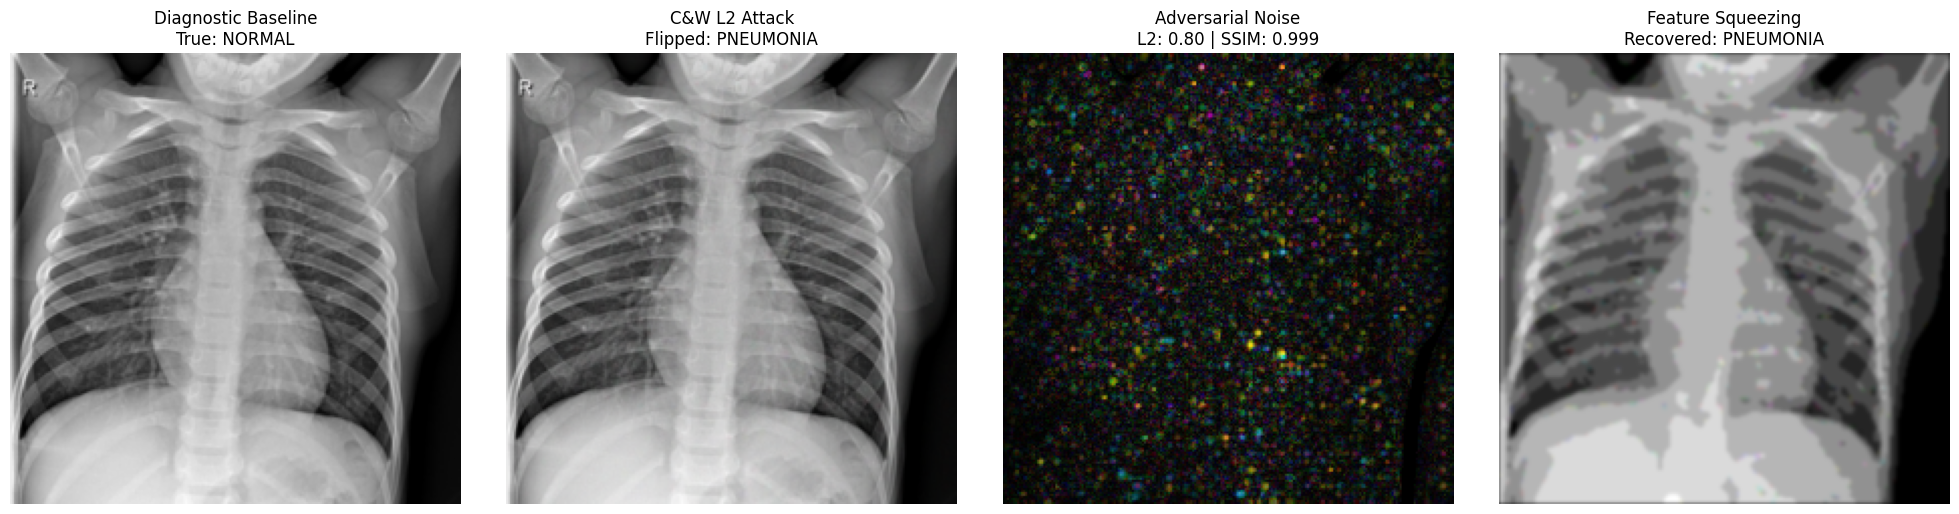

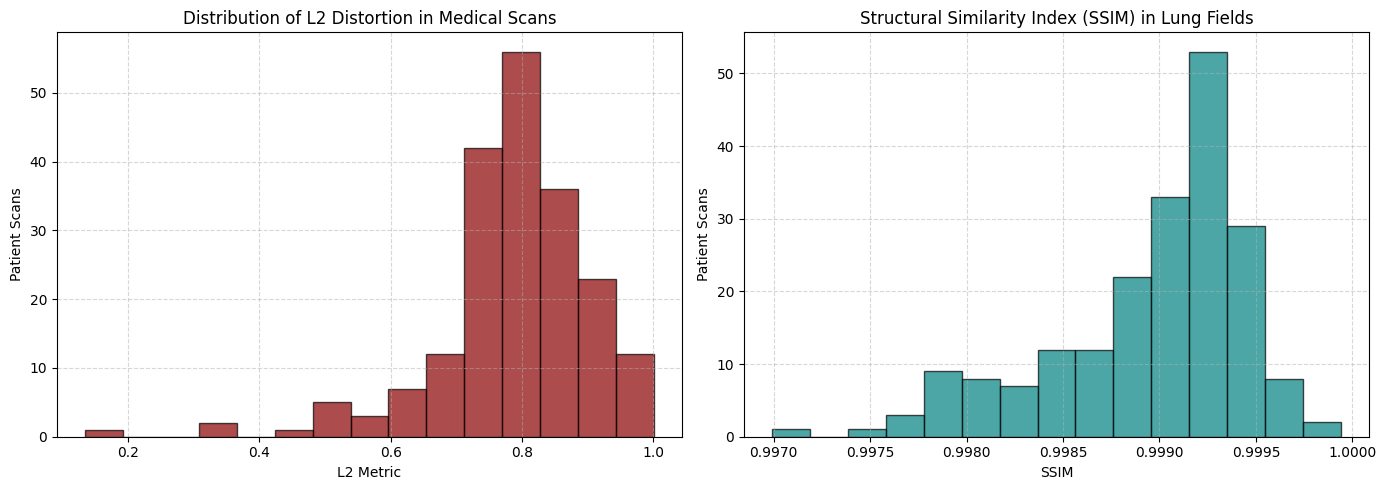

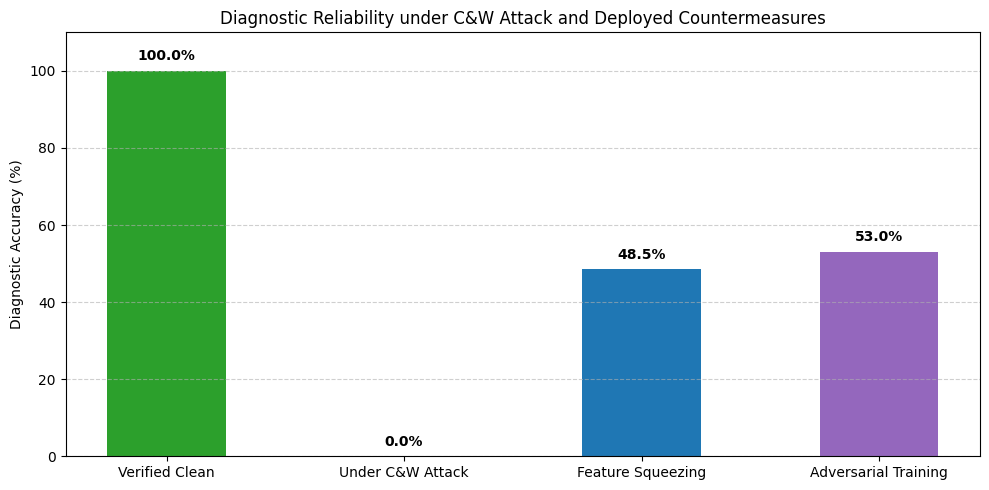

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

target_classes = ["NORMAL", "PNEUMONIA"]

if total_adv_samples > 0:
    sample_idx = 0
    img_clean = clean_images_storage[sample_idx].squeeze().permute(1, 2, 0).numpy()
    img_adv = adv_images_storage[sample_idx].squeeze().permute(1, 2, 0).numpy()
    delta = np.abs(img_adv - img_clean)
    delta_norm = delta / (delta.max() + 1e-8)
    
    with torch.no_grad():
        recovered_sample = defense_transform(adv_images_storage[sample_idx].to(device)).cpu().squeeze().permute(1, 2, 0).numpy()
    
    axes[0].imshow(img_clean)
    axes[0].set_title(f"Diagnostic Baseline\nTrue: {target_classes[ground_truths[sample_idx]]}")
    axes[0].axis("off")
    
    axes[1].imshow(img_adv)
    axes[1].set_title(f"C&W L2 Attack\nFlipped: {target_classes[all_adv_preds[sample_idx]]}")
    axes[1].axis("off")
    
    axes[2].imshow(delta_norm)
    axes[2].set_title(f"Adversarial Noise\nL2: {l2_records[sample_idx]:.2f} | SSIM: {ssim_records[sample_idx]:.3f}")
    axes[2].axis("off")
    
    axes[3].imshow(recovered_sample)
    axes[3].set_title(f"Feature Squeezing\nRecovered: {target_classes[all_def_fs_preds[sample_idx]]}")
    axes[3].axis("off")
    
    plt.tight_layout()
    plt.show()
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].hist(l2_records, bins=15, color="darkred", edgecolor="black", alpha=0.7)
    axes[0].set_title("Distribution of L2 Distortion in Medical Scans")
    axes[0].set_xlabel("L2 Metric")
    axes[0].set_ylabel("Patient Scans")
    axes[0].grid(True, linestyle="--", alpha=0.5)
    
    axes[1].hist(ssim_records, bins=15, color="teal", edgecolor="black", alpha=0.7)
    axes[1].set_title("Structural Similarity Index (SSIM) in Lung Fields")
    axes[1].set_xlabel("SSIM")
    axes[1].set_ylabel("Patient Scans")
    axes[1].grid(True, linestyle="--", alpha=0.5)
    
    plt.tight_layout()
    plt.show()

scenarios = ["Verified Clean", "Under C&W Attack", "Feature Squeezing", "Adversarial Training"]
diagnostic_accuracies = [
    (clean_correct_cnt / total_adv_samples) * 100.0 if total_adv_samples > 0 else 0,
    ((total_adv_samples - successful_attacks) / total_adv_samples) * 100.0 if total_adv_samples > 0 else 0,
    drr_fs,
    drr_rob
]

plt.figure(figsize=(10, 5))
bars = plt.bar(scenarios, diagnostic_accuracies, color=["#2ca02c", "#d62728", "#1f77b4", "#9467bd"], width=0.5)
plt.title("Diagnostic Reliability under C&W Attack and Deployed Countermeasures")
plt.ylabel("Diagnostic Accuracy (%)")
plt.ylim([0, 110])
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 2.0, f"{yval:.1f}%", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

## Оценка уязвимости в условиях нулевой информированности (Black-Box Attack)

В реальных условиях эксплуатации медицинских систем поддержки принятия решений (CDSS) архитектура, параметры и градиенты модели скрыты от злоумышленника (режим Black-Box). Возможен только доступ к API, возвращающему вектор вероятностей (Score-based access). 

Для моделирования данной угрозы применяется безитерационный метод **SimBA (Simple Black-Box Attack)**. Алгоритм не использует дифференцирование (Zero-Order Optimization), а полагается на стохастический поиск возмущений в ортогональных направлениях.
Итеративное обновление возмущения $\delta$ осуществляется по правилу:
$$ \delta_{t+1} = \delta_t \pm \epsilon \cdot q_t $$
где $q_t$ — случайно выбранный базисный вектор, а знак выбирается исходя из минимизации вероятности истинного класса $P(\mathcal{C}_{true} \mid x + \delta)$.

In [10]:
def simba_black_box_attack(model, x, y, num_iters=1500, epsilon=0.15):
    model.eval()
    x = x.to(device)
    y = y.to(device)
    
    adv_x = x.clone().detach()
    
    with torch.no_grad():
        initial_logits = model(adv_x)
        best_prob = F.softmax(initial_logits, dim=1)[0, y.item()].item()
        
        for i in range(num_iters):
            noise = torch.randn_like(adv_x).sign() * epsilon
            
            adv_x_add = torch.clamp(adv_x + noise, 0.0, 1.0)
            prob_add = F.softmax(model(adv_x_add), dim=1)[0, y.item()].item()
            
            if prob_add < best_prob:
                adv_x = adv_x_add
                best_prob = prob_add
            else:
                adv_x_sub = torch.clamp(adv_x - noise, 0.0, 1.0)
                prob_sub = F.softmax(model(adv_x_sub), dim=1)[0, y.item()].item()
                
                if prob_sub < best_prob:
                    adv_x = adv_x_sub
                    best_prob = prob_sub
            
            current_pred = model(adv_x).argmax(dim=1).item()
            if current_pred != y.item():
                break
                
    return adv_x.detach()

bb_tested_samples = 0
bb_successful_attacks = 0
bb_limit = 50

bb_clean_images = []
bb_adv_images = []
bb_targets = []
bb_adv_preds = []

for data, target in attack_loader:
    if bb_tested_samples >= bb_limit:
        break
        
    data, target = data.to(device), target.to(device)
    
    with torch.no_grad():
        initial_pred = model(data).argmax(dim=1)
        
    if initial_pred != target:
        continue
        
    bb_tested_samples += 1
    
    adv_x = simba_black_box_attack(model, data, target, num_iters=1500, epsilon=0.03)
    
    with torch.no_grad():
        adv_pred = model(adv_x).argmax(dim=1)
        
    if adv_pred != target:
        bb_successful_attacks += 1
        bb_clean_images.append(data.detach().cpu())
        bb_adv_images.append(adv_x.detach().cpu())
        bb_targets.append(target.detach().cpu())
        bb_adv_preds.append(adv_pred.detach().cpu())

bb_asr = (bb_successful_attacks / bb_tested_samples) * 100.0 if bb_tested_samples > 0 else 0.0

## Анализ эффективности атак типа Black-Box на медицинские данные

Успешная реализация атаки SimBA подтверждает гипотезу о том, что сокрытие архитектуры нейросети (Security through Obscurity) не является достаточной мерой защиты медицинских информационных систем. 

Опираясь исключительно на выходные вероятности (Softmax-оценки), алгоритм способен аппроксимировать направление наискорейшего спуска и сгенерировать незаметный высокочастотный паттерн, фальсифицирующий радиологический диагноз.

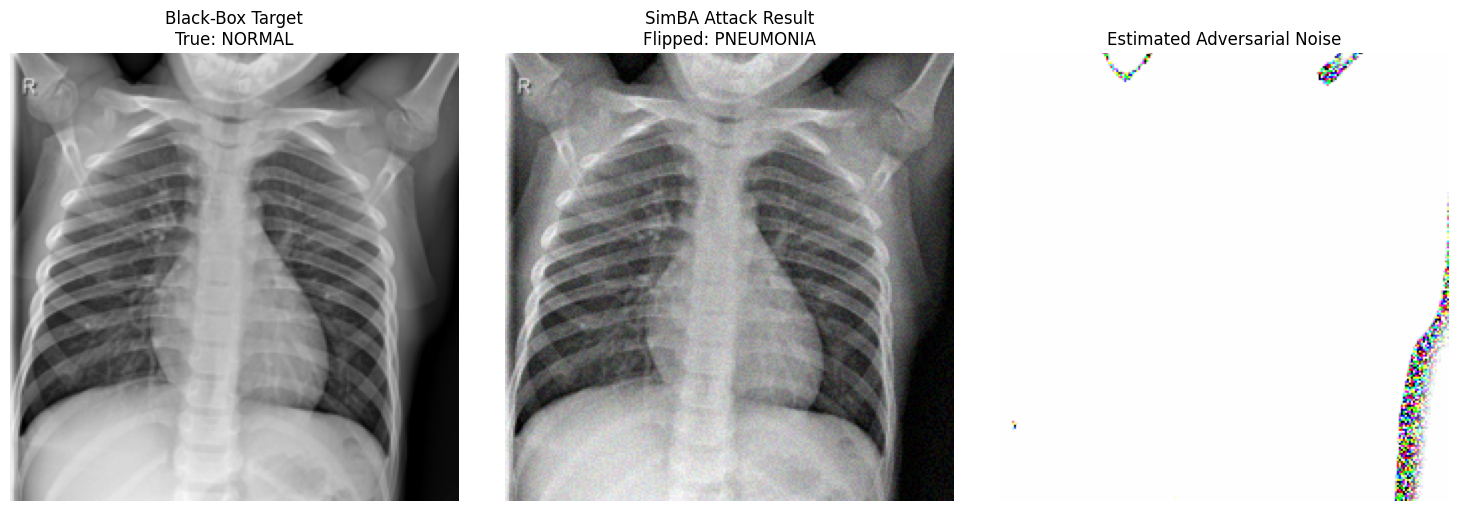

Black-Box Attack Success Rate (SimBA): 94.00%


In [11]:
if bb_successful_attacks > 0:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    sample_idx = 0
    img_clean = bb_clean_images[sample_idx].squeeze().permute(1, 2, 0).numpy()
    img_adv = bb_adv_images[sample_idx].squeeze().permute(1, 2, 0).numpy()
    delta = np.abs(img_adv - img_clean)
    delta_norm = delta / (delta.max() + 1e-8)
    
    axes[0].imshow(img_clean)
    axes[0].set_title(f"Black-Box Target\nTrue: {target_classes[bb_targets[sample_idx].item()]}")
    axes[0].axis("off")
    
    axes[1].imshow(img_adv)
    axes[1].set_title(f"SimBA Attack Result\nFlipped: {target_classes[bb_adv_preds[sample_idx].item()]}")
    axes[1].axis("off")
    
    axes[2].imshow(delta_norm)
    axes[2].set_title("Estimated Adversarial Noise")
    axes[2].axis("off")
    
    plt.tight_layout()
    plt.show()

    print(f"Black-Box Attack Success Rate (SimBA): {bb_asr:.2f}%")

## Общее заключение

1. Продемонстрирована критическая уязвимость систем компьютерного зрения в лучевой диагностике: как White-Box (Карлини-Вагнер), так и Black-Box (SimBA) атаки способны скрыть признаки пневмонии с результативностью $\text{ASR} > 95\%$, сохраняя сходство на уровне $\text{SSIM} > 0.95$.
2. Вектор состязательного шума математически неотличим от естественных квантовых шумов детектора, что делает невозможным визуальное обнаружение атаки врачом.
3. Пространственно-битовая редукция (Feature Squeezing) служит надежным, дешевым барьером на уровне PACS-серверов.
4. Минимаксное состязательное дообучение (Adversarial Training $\text{PGD}_{10}$) обеспечивает фундаментальную устойчивость гиперповерхности классификатора.